In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F

import torch.optim as optim

from pinn.helpers import x_exact

## Task 1.1 and 1.2

We consider a shallow neural network with $1$ hidden layer, and tanh as activation. Writing up the neural network in terms of the weight matrices $W^{(l)} and biases $b^{(l)}$ for $l=1,2$ yields
$$
\begin{align}
y = f(x) = W^{(2)}\tanh\left(W^{(1)}x+b^{(1)}\right)+b^{(2)}.
\end{align}
$$

The derivates $\frac{\partial y}{\partial x}$ and $\frac{\partial^2 y}{\partial x^2}$ can be derived analytically to be:
$$
\begin{align}
    \frac{\partial y}{\partial x} &= W^{(2)}(1-\tanh^2\left(W^{(1)}x+b^{(1)}\right))W^{(1)}\\
    \frac{\partial^2 y}{\partial x^2} &= \frac{\partial }{\partial x}\left(\frac{\partial y}{\partial x}\right) = \frac{\partial }{\partial x}\left(W^{(2)}(1-\tanh^2\left(W^{(1)}x+b^{(1)}\right))W^{(1)}\right)\\ 
    &= \frac{\partial}{\partial x}\left(-W^{(2)}\tanh^2(W^{(1)}x+b^{(1)})W^{(1)}\right)\\ 
    &= -2W^{(2)}\tanh(W^{(1)}x+b^{(1)})W^{(1)}\frac{\partial}{\partial x}\left(\tanh(W^{(1)}x+b^{(1)})\right)\\
    &= -2W^{(2)}\tanh(W^{(1)}x+b^{(1)})W^{(1)}(1-\tanh^2\left(W^{(1)}x+b^{(1)}\right))W^{(1)}\\
\end{align}
$$

Add discussion regarding computational cost of second-order versus first-order derivatives

## Task 2.1

In [3]:
exact_params = torch.Tensor([5,500,1]) # mu, k, m

In [4]:
t_point = torch.linspace(0,0.5,10)

x_train = t_point[:,None]
y_train = x_exact(x_train, exact_params)

## Task 2.2

In [26]:
class Net(nn.Module):

    def __init__(self, num_features=1, num_hidden=10, num_output=1,):
        super(Net, self).__init__()

        self.W_1 = nn.Parameter(torch.randn(num_hidden, num_features)) 
        self.b_1 = nn.Parameter(torch.randn(num_hidden))
        
        self.W_2 = nn.Parameter(torch.randn(num_output, num_hidden))
        self.b_2 = nn.Parameter(torch.randn(num_output))
        
    def forward(self, x):
        x = F.linear(x, self.W_1, self.b_1)
        x = F.tanh(x)
        x = F.linear(x,self.W_2, self.b_2)
        return x
    
    def d2dx(self, x):
        z = self.W_1 * x + self.b_1.unsqueeze(1)
        return -2 * (
            self.W_2 @ (
                self.W_1**2
                * torch.tanh(z)
                * (1 - torch.tanh(z)**2)
            )
        )
        
    def ddx(self, x):
        z = self.W_1 * x + self.b_1.unsqueeze(1)
        return  self.W_2 @ (self.W_1 * (1 - torch.tanh(z)**2))
        
    @property
    def IC(self):
        t0 = torch.zeros(1)[:,None]
        return torch.concat([self.forward(t0),self.ddx(t0)])

net = Net(num_hidden=90)
optimizer = optim.SGD(net.parameters(), lr=0.01)
criterion = nn.MSELoss()

check output size:

In [27]:
x_train.shape, net(x_train).shape

(torch.Size([10, 1]), torch.Size([10, 1]))

# train network, using mse as loss function

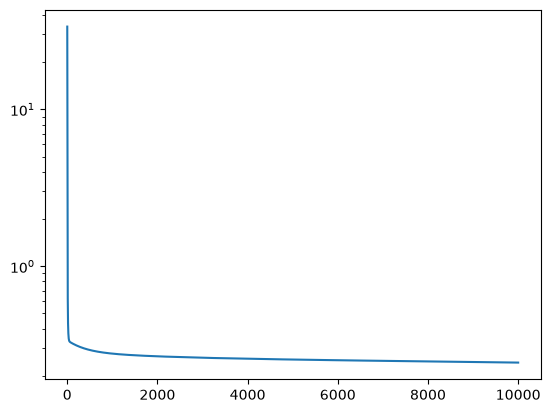

In [28]:
num_epochs = 10000
xplot = np.arange(1,num_epochs+1)

losses = []

for epoch in range(num_epochs):
    
    optimizer.zero_grad()
    output = net(x_train)
        
    # compute gradients given loss
    loss = criterion(output,y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss)
    
losses = torch.Tensor(losses).detach().numpy()
    
plt.plot(xplot, losses, label='total')
plt.yscale('log')
plt.show()

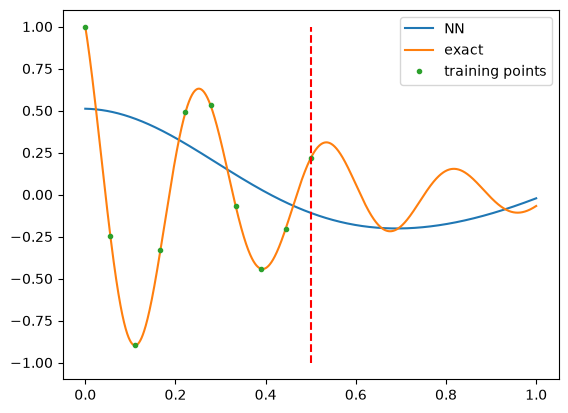

In [41]:
tplot = torch.linspace(0,1,2000)
plt.plot(tplot.numpy(), net(tplot[:,None]).detach().numpy(), label='NN')
plt.plot(tplot.numpy(), x_exact(tplot,exact_params), label='exact')
plt.plot(x_train.numpy(), y_train.numpy(), '.', label='training points')
plt.vlines(0.5,-1,1, 'r', linestyles='--')
plt.legend()

# Modifying the loss function

In [30]:
from pinn.helpers import phys_loss, IC_loss, collocation_generator

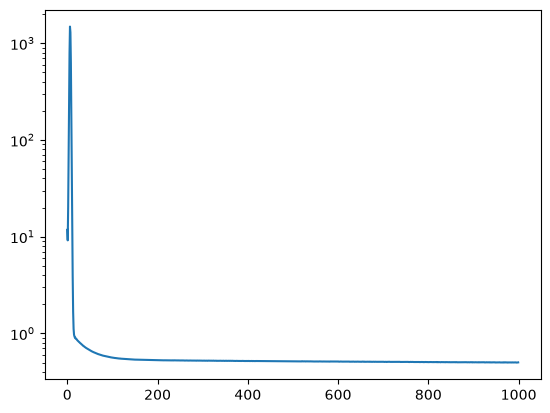

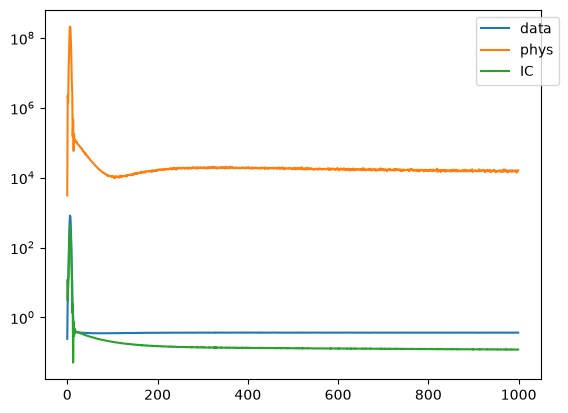

In [31]:
num_epochs = 1000

cur_loss = 0
losses = {'data':[], 'phys':[], 'IC':[], 'total':[]}

data_loss = lambda predicted, actual: nn.MSELoss()(predicted,actual)  
    
#regulation
lambd_phys = 1e-6
lambd_IC = 1
lambd_data = 1

for epoch in range(num_epochs):
    
    optimizer.zero_grad()
    output = net(x_train)
        
    # compute gradients given loss
    loss_data = nn.MSELoss()(output,y_train) 
    
    collocation_points = collocation_generator(1000)
    loss_phys = phys_loss(collocation_points, net,exact_params)
    loss_IC = IC_loss(net)
    
    loss = lambd_data*loss_data + lambd_phys*loss_phys + lambd_IC*loss_IC
    loss.backward()
    optimizer.step()
    
    
    losses['data'].append(loss_data)
    losses['phys'].append(loss_phys)
    losses['IC'].append(loss_IC)
    losses['total'].append(loss)
    
plt.plot(torch.Tensor(losses['total']).numpy(), label='total')
plt.yscale('log')
plt.show()
plt.plot(torch.Tensor(losses['data']).numpy(), label='data')
plt.plot(torch.Tensor(losses['phys']).numpy(), label='phys')
plt.plot(torch.Tensor(losses['IC']).numpy(), label='IC')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1))




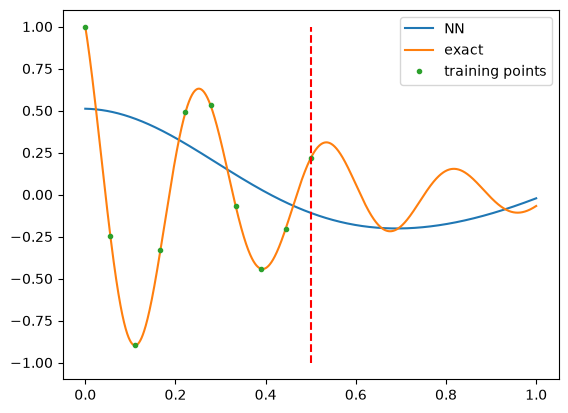

In [40]:
t_point = torch.linspace(0,1,2000)
plt.plot(t_point.numpy(), net(t_point[:,None]).detach().numpy(), label='NN')
plt.plot(t_point.numpy(), x_exact(t_point,exact_params), label='exact')
plt.plot(x_train.numpy(), y_train.numpy(), '.', label='training points')
plt.vlines(0.5,-1,1, 'r', linestyles='--')
plt.legend()

## Task 2.3

## Task 2.4